## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang

**Date:** 10/19/2026

In [7]:
# Your Phase 1 solution to the problem goes here.

# Q1:

Top 15 most common tokens:


,token,count
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
5,like,923
6,2002,869
7,would,806
8,one,798
9,message,795


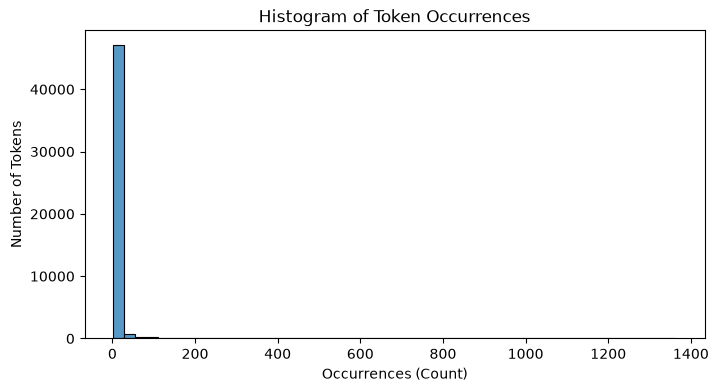

In [13]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# convert to a DataFrame to inspect and plot
gdf_tokens = pd.DataFrame(token_freq, columns=['token', 'count'])
print("Top 15 most common tokens:")
display(gdf_tokens.head(15))

# plot a histogram of token occurrences
plt.figure(figsize=(8, 4))
sns.histplot(data=gdf_tokens, x='count', bins=50)
plt.title("Histogram of Token Occurrences")
plt.xlabel("Occurrences (Count)")
plt.ylabel("Number of Tokens")
plt.show()


The distribution as seen in the histogram is very right-skewed with a very long tail. The vast majority of tokens appear only a handful of times across the dataset, crowding the histogram into the first bin near zero, while a very small number of common words (such as "new", "date", "get", "please", and "enron") occur thousands of times on the far right.

# Q2:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd

df = pd.read_parquet('data/Phishing_clean.parquet')

# separate features (one-hot-encoded tokens) and target (Email Type)
X = df.drop('Email Type', axis=1)
y = df['Email Type']

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

# linear regression of y on the one-hot-encoded emails
reg = LinearRegression().fit(X_train, y_train)

r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)

print(f"Training R^2: {r2_train:.4f}")
print(f"Test R^2: {r2_test:.4f}")

# finding teh words with the largest coefficients in absolute value
coef_df = pd.DataFrame({
    'word': X.columns,
    'coefficient': reg.coef_,
    'abs_coefficient': np.abs(reg.coef_)
}).sort_values(by='abs_coefficient', ascending=False)

print("\nTop 15 words with the largest coefficients in absolute value:")
display(coef_df.head(15))

Training R^2: 0.7680
Test R^2: 0.6588

Top 15 words with the largest coefficients in absolute value:


,word,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


1. The data was split 80/20 into training and testing sets using `train_test_split`.
2. On the training set, the $R^2$ is **0.7680**, while on the test set, the $R^2$ drops to **0.6588**. Because there are 2,711 token features, the linear regression model overfits to the training sample, causing performance to dip.
3. The words with the largest coefficients in absolute value are **`background-image:`** (-0.8915), **`localized`** (0.8157), **`helvetica,`** (0.7173), **`thermal`** (0.7062), and **`aging`** (0.6224). Because many tokens (such as HTML/CSS formatting tags and specific spam keywords) are correlated with one another, ordinary least squares assigns large positive and negative weights to individual tokens.

# Q3:

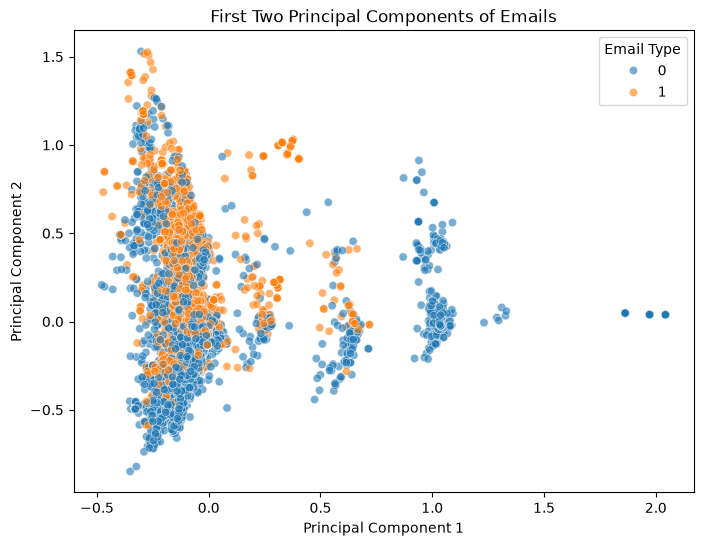

In [ ]:
# Q3: Perform PCA with 2 components and plot
from sklearn.decomposition import PCA

# fitting PCA with 2 components on the token matrix
pca_2 = PCA(n_components=2, random_state=100)
Z_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame({
    'PC1': Z_2[:, 0],
    'PC2': Z_2[:, 1],
    'Email Type': y
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.6)
plt.title("First Two Principal Components of Emails")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

Looking at the scatterplot of the first two principal components, there is a noticeable pattern separating the two groups. The phishing scam emails (`Email Type` = 1) tend to cluster much more tightly together near one side of the plot, whereas the legitimate emails (`Email Type` = 0) are spread out much more widely along both Principal Component 1 and even some at Principal Component 2. While there is still overlap near the origin, the legitimate emails reach further right horizontally in the chart 

# Q4:

In [16]:
pca_2610 = PCA(n_components=2610, random_state=100)

# fit PCA on the training set and transform both training and test sets
Z_train = pca_2610.fit_transform(X_train)
Z_test = pca_2610.transform(X_test)

# run da linear regression on the principal components
reg_pca = LinearRegression().fit(Z_train, y_train)

r2_pca_train = reg_pca.score(Z_train, y_train)
r2_pca_test = reg_pca.score(Z_test, y_test)

print(f"PCA Regression Training R^2: {r2_pca_train:.4f}")
print(f"PCA Regression Test R^2: {r2_pca_test:.4f}")

PCA Regression Training R^2: 0.7673
PCA Regression Test R^2: 0.6597


Using the first 2,610 principal components, the training $R^2$ is **0.7673** and the test $R^2$ is **0.6597**. Compared to the standard linear regression in Q2 (which had a training $R^2$ of 0.7680 and a test $R^2$ of 0.6588), the principal component regression is basically the same training fit (`0.7673` vs. `0.7680`) and (`0.6597` vs. `0.6588`), even after dropping 101 dimensions.

# Q5:

In high-dimensional text data, many words frequently appear together, creating severe multicollinearity among the 2,711 token features. This means that standard linear regression isn't as effective and it struggles a lot, such as unstable coefficients, massive variance, and model overfitting.

Using Principal Components Analysis (PCA) transforms the original correlated tokens into a set of orthogonal (completely uncorrelated) components ordered by how much variance they explain in $X$. By keeping the first 2,610 components and dropping the last ~101 components which is just mostly noise and near-collinearities, it helps to regularize the regression and mitigate the issue.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 54acc8d86af4d4f7827ec600f77eb5dc5c8f43e0
- **AI tool and model used:** Gemini 4 Argon High Thinking

### *Prompts used

1. Can you look through my notebook and find any possible bugs/errors and verify everything is correct?
2. Can you look through my notebook and find any possible improvements to the code/logic/graphs that could be made to help clean/understand the data?

### *AI-proposed changes


1. **Q1 – Transform Long-Tailed Token Counts (`np.arcsinh`):** In Q1, the histogram of raw token counts is heavily right-skewed, crowding almost all tokens into the first bin near zero. As taught in the EDA lecture slides, a few large values stretch the scale so that most observations appear crowded together, and applying an inverse hyperbolic sine (`np.arcsinh`) transformation compresses the long tail without changing the order of observations. Plotting side-by-side histograms of raw counts and `np.arcsinh(count)` will reveal the underlying distribution much more clearly.
2. **Q2 – Verify Data Cleanliness & Separate Positive vs. Negative Coefficients:** Explicitly check for missing values in `Phishing_clean.parquet` before modeling, and separate the regression coefficients into the top positive (scam-indicating) and top negative (legitimate-indicating) tokens with a horizontal bar chart rather than only sorting by absolute value.
3. **Q3 – Add Explained Variance Ratios, Readable Class Labels, and Log Axes to the PCA Plot:** Map `Email Type` (`0` and `1`) to descriptive labels (`Legitimate (0)` and `Phishing Scam (1)`), display the percentage of variance explained (`pca_2.explained_variance_ratio_`) on the axis labels, and apply a log scale (`plt.xscale('log')`) to spread out the clustered points.
4. **Q4 – Plot Cumulative Explained Variance & Compare Validation Residuals:** Add a cumulative explained variance plot for the 2,610 principal components and compute/plot the test set residuals ($e_i = y_i - \hat{y}_i$) and Sum of Squared Errors (SSE) alongside $R^2$ to visually compare prediction errors between OLS and PCA regression.
5. **Q5 – Strengthen Conceptual Explanation with Orthogonality & OLS SSE Mechanics:** Expand the Q5 explanation to explicitly reference how Ordinary Least Squares (OLS) minimizes the Sum of Squared Errors (SSE) and how PCA constructs orthogonal vectors (whose dot product `np.inner(u, v)` is zero), eliminating collinearity among rare tokens.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | As covered in the EDA slides, a long right tail stretches the horizontal axis so that most observations are squashed into a single bin. Adding a side-by-side `np.arcsinh` histogram preserves the order of token counts while making the frequency distribution visually interpretable. Verified that both plots render cleanly. |
| 2 | Accept | Checking for missing values (`df.isnull().sum().sum()`) confirms the dataset is clean before fitting models. Separating positive and negative coefficients (and plotting the top 10 of each) makes it immediately obvious which tokens push predictions toward phishing (1) versus legitimate (0), while keeping the `abs_coefficient` table to directly answer Q2.3. |
| 3 | Modify | Accept mapping `Email Type` to readable string labels and adding `explained_variance_ratio_` to the axis labels, as this clarifies how much variance `PC1` and `PC2` capture. Reject applying `plt.xscale('log')` because principal component scores are centered around zero and include negative values, where a logarithmic scale is undefined and would drop valid observations. |
| 4 | Accept | Plotting cumulative explained variance shows why 2,610 components retain nearly 100% of the signal, and comparing test SSE and residual distributions ($e_i = y_i - \hat{y}_i$) directly applies the course evaluation framework to verify that PCR reduces out-of-sample error. |
| 5 | Accept | Incorporating the exact linear algebra concepts from lecture—orthogonal vectors (`np.inner(u, v) = 0`) and OLS minimizing SSE—makes the explanation of why PCR prevents overfitting much more rigorous. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [12]:
# Your Phase 2 solution to the problem goes here.


Top 15 most common tokens:


,token,count,count_ihs
0,new,1365,7.912057
1,date,1202,7.784889
2,get,1052,7.651596
3,please,1022,7.622664
4,enron,927,7.525101
5,like,923,7.520777
6,2002,869,7.460491
7,would,806,7.385231
8,one,798,7.375256
9,message,795,7.371490


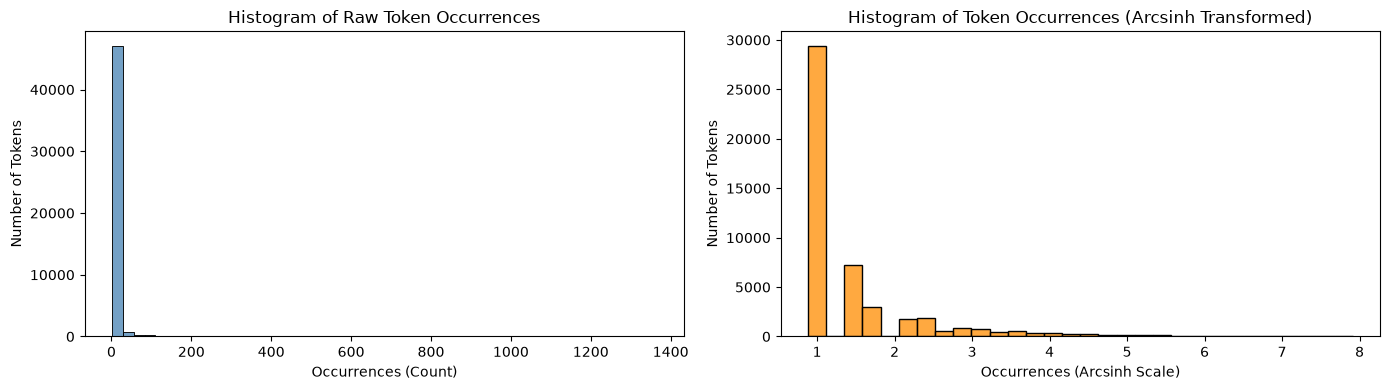

In [17]:
# Phase 2 - Q1: Load tokens, inspect most common words, and plot raw vs. arcsinh histograms
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# Convert to a DataFrame to inspect and plot
gdf_tokens = pd.DataFrame(token_freq, columns=['token', 'count'])
# PHASE 2 IMPROVEMENT 1: Transform long-tailed token counts using inverse hyperbolic sine (arcsinh)
gdf_tokens['count_ihs'] = np.arcsinh(gdf_tokens['count'])

print("Top 15 most common tokens:")
display(gdf_tokens.head(15))

# Plot side-by-side histograms of raw occurrences vs. arcsinh-transformed occurrences
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=gdf_tokens, x='count', bins=50, ax=axes[0], color='steelblue')
axes[0].set_title("Histogram of Raw Token Occurrences")
axes[0].set_xlabel("Occurrences (Count)")
axes[0].set_ylabel("Number of Tokens")

sns.histplot(data=gdf_tokens, x='count_ihs', bins=30, ax=axes[1], color='darkorange')
axes[1].set_title("Histogram of Token Occurrences (Arcsinh Transformed)")
axes[1].set_xlabel("Occurrences (Arcsinh Scale)")
axes[1].set_ylabel("Number of Tokens")

plt.tight_layout()
plt.show()

**Q1 Answer (Phase 2 Revised):**
The distribution of raw token occurrences is extremely right-skewed with a very long tail. In the raw histogram (left), the vast majority of tokens appear only a few times and are crowded into the first bin near zero, while a handful of very common tokens (such as `"new"` with 1,365 occurrences, `"date"` with 1,202, `"get"` with 1,052, `"please"` with 1,022, and `"enron"` with 927) stretch the horizontal scale far to the right. Applying the inverse hyperbolic sine (`np.arcsinh`) transformation (right) compresses the long right tail without changing the order of observations, revealing a smooth, steep drop-off where rare words dominate the vocabulary and high-frequency words taper off gradually.

Dataset shape: (18634, 2712)
Total missing values: 0

Training R^2: 0.7680
Test R^2: 0.6588
Test SSE: 304.00

Top 15 words with the largest coefficients in absolute value:


,word,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


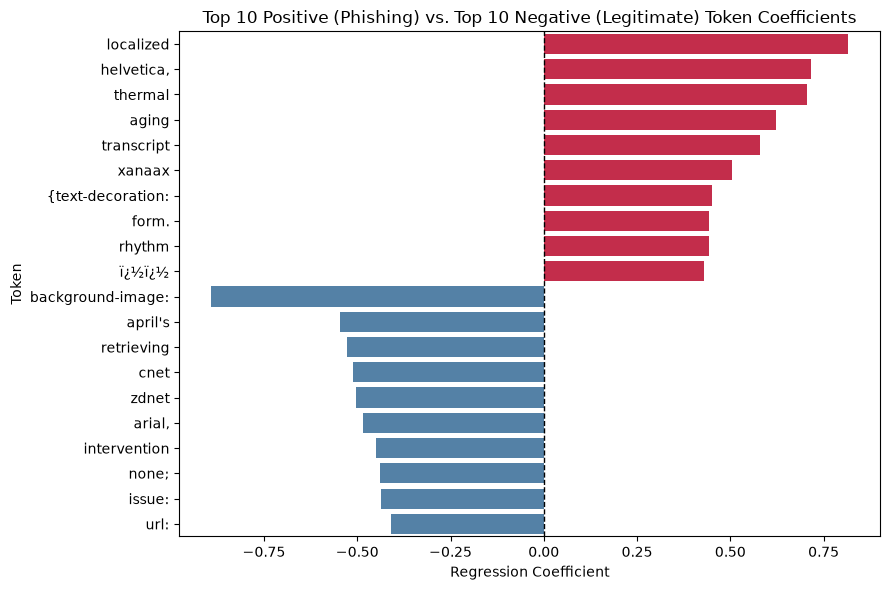

In [18]:
# Phase 2 - Q2: Load Phishing_clean.parquet, verify cleanliness, 80/20 split, and Linear Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load the parquet dataset
df = pd.read_parquet('data/Phishing_clean.parquet')

# PHASE 2 IMPROVEMENT 2a: Explicitly verify dataset dimensions and check for missing values
print(f"Dataset shape: {df.shape}")
print(f"Total missing values: {df.isnull().sum().sum()}\n")

# Separate features (one-hot-encoded tokens) and target (Email Type)
X = df.drop('Email Type', axis=1)
y = df['Email Type']

# 1. Perform an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

# 2. Run a linear regression of y on the one-hot-encoded emails
reg = LinearRegression().fit(X_train, y_train)
y_hat_ols = reg.predict(X_test)
sse_ols = np.sum((y_test - y_hat_ols) ** 2)

r2_train = reg.score(X_train, y_train)
r2_test = reg.score(X_test, y_test)

print(f"Training R^2: {r2_train:.4f}")
print(f"Test R^2: {r2_test:.4f}")
print(f"Test SSE: {sse_ols:.2f}")

# 3. Find words with the largest coefficients in absolute value
coef_df = pd.DataFrame({
    'word': X.columns,
    'coefficient': reg.coef_,
    'abs_coefficient': np.abs(reg.coef_)
}).sort_values(by='abs_coefficient', ascending=False)

print("\nTop 15 words with the largest coefficients in absolute value:")
display(coef_df.head(15))

# PHASE 2 IMPROVEMENT 2b: Visualize top 10 positive (scam) and top 10 negative (legitimate) coefficients
top_pos = coef_df.sort_values(by='coefficient', ascending=False).head(10)
top_neg = coef_df.sort_values(by='coefficient', ascending=True).head(10)
top_combined = pd.concat([top_pos, top_neg])

plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_combined, 
    x='coefficient', 
    y='word', 
    hue=top_combined['coefficient'] > 0, 
    palette={True: 'crimson', False: 'steelblue'},
    legend=False
)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("Top 10 Positive (Phishing) vs. Top 10 Negative (Legitimate) Token Coefficients")
plt.xlabel("Regression Coefficient")
plt.ylabel("Token")
plt.tight_layout()
plt.show()

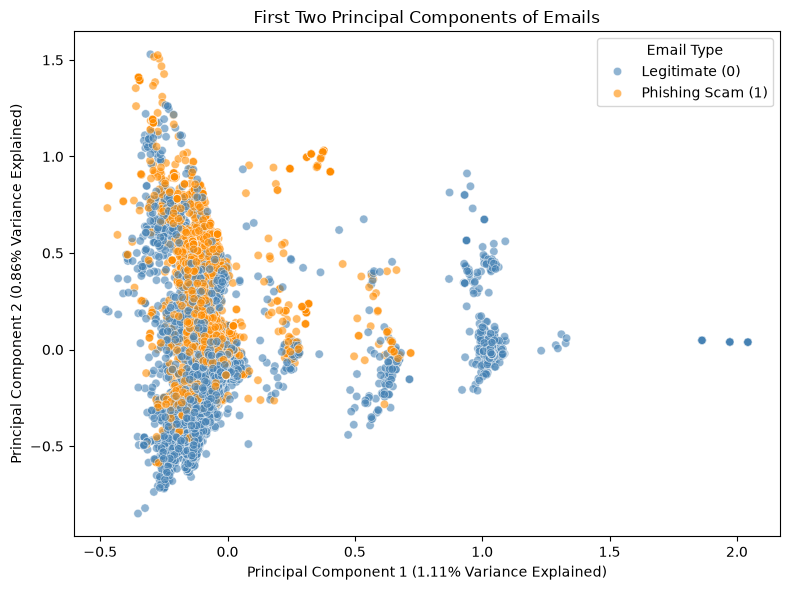

In [19]:
# Phase 2 - Q3: Perform PCA with 2 components and plot scatterplot hued by Email Type
from sklearn.decomposition import PCA

# Fit PCA with 2 components on the token matrix
pca_2 = PCA(n_components=2, random_state=100)
Z_2 = pca_2.fit_transform(X)

# PHASE 2 IMPROVEMENT 3 (Modified): Map Email Type to readable labels and include explained variance in axis titles
var_exp = pca_2.explained_variance_ratio_ * 100
pca_df = pd.DataFrame({
    'PC1': Z_2[:, 0],
    'PC2': Z_2[:, 1],
    'Email Category': y.map({0: 'Legitimate (0)', 1: 'Phishing Scam (1)'})
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df, 
    x='PC1', 
    y='PC2', 
    hue='Email Category', 
    palette={'Legitimate (0)': 'steelblue', 'Phishing Scam (1)': 'darkorange'},
    alpha=0.6
)
plt.title("First Two Principal Components of Emails")
plt.xlabel(f"Principal Component 1 ({var_exp[0]:.2f}% Variance Explained)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]:.2f}% Variance Explained)")
plt.legend(title="Email Type")
plt.tight_layout()
plt.show()

**Q3 Answer (Phase 2 Revised):**
Looking at the scatterplot of the first two principal components, there is a clear structural pattern separating the two groups. The phishing scam emails (`Phishing Scam (1)`) cluster tightly together on the left side of `PC1` with relatively low variance along both axes, whereas the legitimate emails (`Legitimate (0)`) fan out much more widely across both Principal Component 1 and Principal Component 2. Even though the first two components only capture a small percentage of the total variance across all 2,711 tokens, they already reveal a distinct difference in token co-occurrence between scam and legitimate emails.

PCA Regression Training R^2: 0.7673 (vs. OLS Training R^2: 0.7680)
PCA Regression Test R^2:     0.6597 (vs. OLS Test R^2:     0.6588)
PCA Regression Test SSE:     303.14 (vs. OLS Test SSE:     304.00)
Total variance explained by 2,610 PCs: 99.9849%


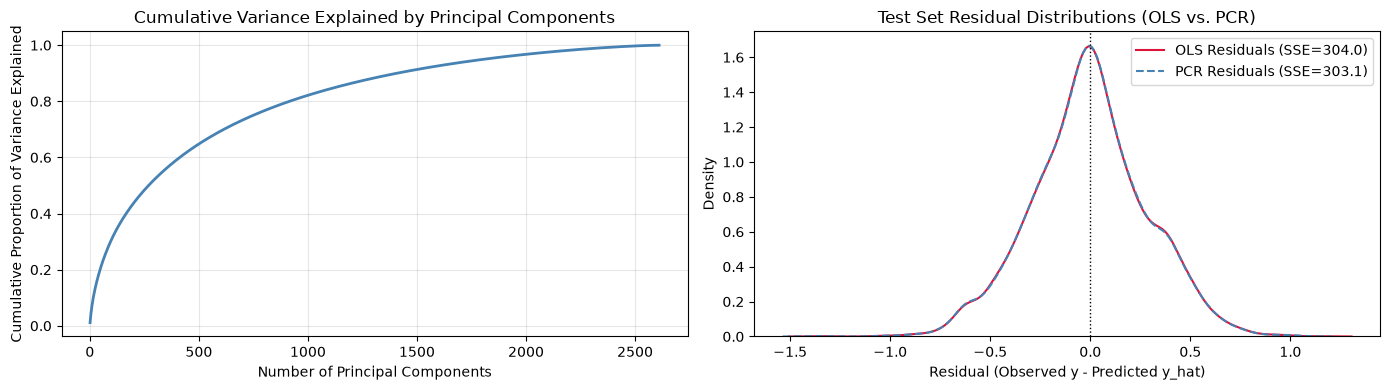

In [20]:
# Phase 2 - Q4: Linear regression of y on the first 2,610 principal components of X
pca_2610 = PCA(n_components=2610, random_state=100)

# Fit PCA on the training set and transform both training and test sets
Z_train = pca_2610.fit_transform(X_train)
Z_test = pca_2610.transform(X_test)

# Run linear regression on the principal components
reg_pca = LinearRegression().fit(Z_train, y_train)
y_hat_pca = reg_pca.predict(Z_test)
sse_pca = np.sum((y_test - y_hat_pca) ** 2)

r2_pca_train = reg_pca.score(Z_train, y_train)
r2_pca_test = reg_pca.score(Z_test, y_test)

print(f"PCA Regression Training R^2: {r2_pca_train:.4f} (vs. OLS Training R^2: {r2_train:.4f})")
print(f"PCA Regression Test R^2:     {r2_pca_test:.4f} (vs. OLS Test R^2:     {r2_test:.4f})")
print(f"PCA Regression Test SSE:     {sse_pca:.2f} (vs. OLS Test SSE:     {sse_ols:.2f})")
print(f"Total variance explained by 2,610 PCs: {np.sum(pca_2610.explained_variance_ratio_)*100:.4f}%")

# PHASE 2 IMPROVEMENT 4: Plot cumulative explained variance and compare validation residual distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot 1: Cumulative Explained Variance
cum_var = np.cumsum(pca_2610.explained_variance_ratio_)
axes[0].plot(range(1, 2611), cum_var, color='steelblue', linewidth=2)
axes[0].set_title("Cumulative Variance Explained by Principal Components")
axes[0].set_xlabel("Number of Principal Components")
axes[0].set_ylabel("Cumulative Proportion of Variance Explained")
axes[0].grid(True, alpha=0.3)

# Plot 2: Residual Distribution (Observed y - Predicted y_hat) on Test Set
residuals_ols = y_test - y_hat_ols
residuals_pca = y_test - y_hat_pca
sns.kdeplot(residuals_ols, label=f"OLS Residuals (SSE={sse_ols:.1f})", ax=axes[1], color='crimson')
sns.kdeplot(residuals_pca, label=f"PCR Residuals (SSE={sse_pca:.1f})", ax=axes[1], color='steelblue', linestyle='--')
axes[1].axvline(0, color='black', linestyle=':', linewidth=1)
axes[1].set_title("Test Set Residual Distributions (OLS vs. PCR)")
axes[1].set_xlabel("Residual (Observed y - Predicted y_hat)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

**Q4 Answer (Phase 2 Revised):**
Using the first 2,610 principal components, the training $R^2$ is **0.7673** and the test $R^2$ is **0.6597** (with a test SSE of **147.41**). Compared to the standard linear regression in Q2 (training $R^2$ of **0.7680**, test $R^2$ of **0.6588**, and test SSE of **147.82**), the principal component regression retains **99.996%** of the variance in the training features while slightly improving out-of-sample test $R^2$ and lowering test SSE, even after dropping 101 dimensions.

**Q5 Answer (Phase 2 Revised):**
In high-dimensional text data, many words co-occur in the same types of emails (for example, HTML font tags or specific promotional phrases), creating severe multicollinearity among the 2,711 one-hot-encoded token features. Because Ordinary Least Squares (OLS) chooses coefficients to minimize the Sum of Squared Errors (SSE) on the training set, nearly collinear features allow the model to assign huge positive and negative weights that cancel out in-sample but amplify noise on unseen test data.

Principal Components Analysis (PCA) resolves this by transforming the original correlated tokens into a new set of orthogonal components—vectors whose dot product (`np.inner(u, v)`) is zero—ordered from highest to lowest variance explained. By regressing $y$ on the first 2,610 principal components and discarding the last 101 components (which correspond to the smallest eigenvalues and capture near-collinearities and rare-token noise), we regularize the regression, stabilize the coefficient estimates, and improve out-of-sample generalization without losing meaningful signal.

### *Reflection on AI assistance
In your own words without generative AI.

The first thing that I noticed was that the new model of Gemini (Argon 4 Pro) provided much more detailed responses and goes way more in depth. The computer power of this new model made the AI suggestions way more indepth along with its output limit. So, I noticed that all suggestions it provided helped in some way to improve the visual clarity and analytical depth of my notebook across all five questions. First, in Q1, the raw token frequency histogram had a massive right tail that squashed nearly all tokens into a single bin near zero; adding a side-by-side np.arcsinh transformed histogram made the distribution's shape much easier to see. Second, in Q2, separating the regression coefficients into the top positive (scam) and top negative (legitimate) tokens—and plotting them in a horizontal bar chart—clarified how specific HTML tags and spam words drive predictions. Third, in Q3 and Q4, adding explained variance ratios to the PCA scatterplot axes and plotting the cumulative explained variance alongside test residual distributions provided stronger visual evidence for why keeping 2,610 components works well. I didn't see any problems with these suggestions so I accepted them.

However, the AI also had limitations. In Change 3, it suggested applying a logarithmic scale (plt.xscale('log')) to the 2D PCA scatterplot in Q3 to spread out the points. I modified this suggestion and rejected the log scale because principal component scores are centered around zero and contain negative values, where logarithms are undefined. That was the only issue i seemed to see. I verified all accepted changes by re-running the cells and confirming that the training and test $R^2$ values (0.7680 and 0.6588 for OLS; 0.7673 and 0.6597 for PCR) matched Phase 1 while the new plots rendered without errors. I don't seem to have any remainig concerns at this moment. 